In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

**Veri Temizleme && Eksik Data**

In [ ]:
# verilerimizi pandas ile çekiyoruz
run_times=pd.read_csv("/content/healthcare-dataset-stroke-data (1).csv")
run_times

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0


In [ ]:
# verilerin tipini kontrol ediyoruz
run_times.dtypes

,0
id,int64
gender,object
age,float64
hypertension,int64
heart_disease,int64
ever_married,object
work_type,object
Residence_type,object
avg_glucose_level,float64
bmi,float64


In [ ]:
# değerlerimizin kolon değerlerini info metodu  ile kontrol ediyoruz
run_times.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [ ]:
# medeni hallerinde daha önce evli olup olmadığı değerlerini bool e çevirdik
run_times['ever_married'] = run_times['ever_married'].map({'Yes': True, 'No': False})
run_times['ever_married'].dtype

dtype('bool')

In [ ]:
# Veri kümesindeki eksik değerleri kontrol ediyoruz
run_times.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


In [ ]:
# 'bmi' sütunundaki eksik değerleri ortalama ile dolduruyoruz
mean_bmi = run_times['bmi'].mean()
run_times['bmi'].fillna(mean_bmi, inplace=True)

# Eksik değerleri tekrar kontrol ediyoruz
run_times.isnull().sum()

/tmp/ipython-input-2953126164.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  run_times['bmi'].fillna(mean_bmi, inplace=True)


,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0


In [ ]:
# sigara içilme sütununda bilinmeyenleri kontrol ediyoruz
unknown_smoking_status_count = (run_times['smoking_status'] == 'Unknown').sum()
print(f"'smoking_status' sütunundaki 'Unknown' sayısı: {unknown_smoking_status_count}")

'smoking_status' sütunundaki 'Unknown' sayısı: 1544


In [ ]:
# 'smoking_status' sütunundaki 'Unknown' dışındaki mod değerini hesaplama
mode_smoking_status = run_times[run_times['smoking_status'] != 'Unknown']['smoking_status'].mode()[0]

# 'Unknown' değerlerini mod ile dolduruyoruz
run_times['smoking_status'] = run_times['smoking_status'].replace('Unknown', mode_smoking_status)

# Şimdi tekrar sigara içme sütunun kontrol edelim
unknown_smoking_status_count_after = (run_times['smoking_status'] == 'Unknown').sum()
print(f"'smoking_status' sütunundaki 'Unknown' sayısı (doldurulduktan sonra): {unknown_smoking_status_count_after}")

'smoking_status' sütunundaki 'Unknown' sayısı (doldurulduktan sonra): 0


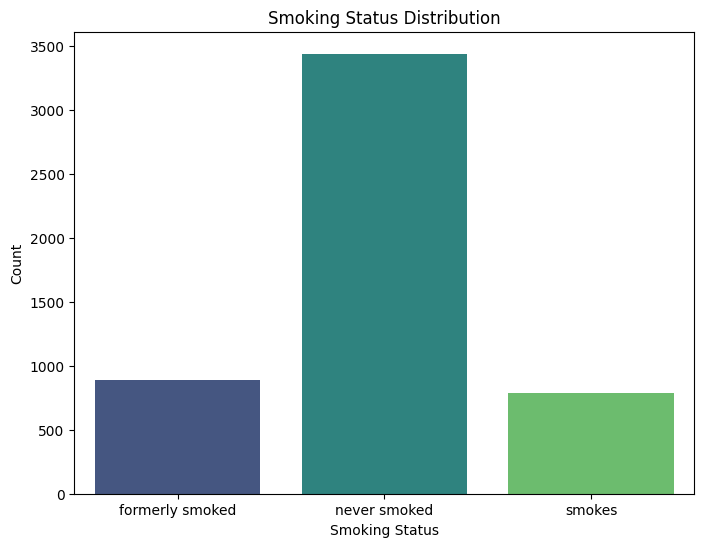

In [ ]:
# 'smoking_status' sütununun dağılımını görselleştirdik
plt.figure(figsize=(8, 6))
sns.countplot(data=run_times, x='smoking_status', hue='smoking_status', palette='viridis', legend=False)
plt.title('Smoking Status Distribution')
plt.xlabel('Smoking Status')
plt.ylabel('Count')
plt.show()

In [ ]:
# Diğer sütunlardaki eksik değerleri kontrol ediyoruz
run_times.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0


In [ ]:
# kategorik sütunlarda tutarsızlıkları bulma
run_times['gender'].value_counts()

,count
gender,
Female,2994
Male,2115
Other,1


In [ ]:
run_times['work_type'].value_counts()

,count
work_type,
Private,2925
Self-employed,819
children,687
Govt_job,657
Never_worked,22


In [ ]:
run_times['Residence_type'].value_counts()

,count
Residence_type,
Urban,2596
Rural,2514


In [ ]:
# sayısal sütunlarda tutarsızlık bulma
run_times.describe

<bound method NDFrame.describe of          id  gender   age  hypertension  heart_disease  ever_married  \
0      9046    Male  67.0             0              1          True   
1     51676  Female  61.0             0              0          True   
2     31112    Male  80.0             0              1          True   
3     60182  Female  49.0             0              0          True   
4      1665  Female  79.0             1              0          True   
...     ...     ...   ...           ...            ...           ...   
5105  18234  Female  80.0             1              0          True   
5106  44873  Female  81.0             0              0          True   
5107  19723  Female  35.0             0              0          True   
5108  37544    Male  51.0             0              0          True   
5109  44679  Female  44.0             0              0          True   

          work_type Residence_type  avg_glucose_level        bmi  \
0           Private          Urban             228.69  36.600000   
1     Self-employed          Rural             202.21  28.893237   
2           Private          Rural             105.92  32.500000   
3           Private          Urban             171.23  34.400000   
4     Self-employed          Rural             174.12  24.000000   
...             ...            ...                ...        ...   
5105        Private          Urban              83.75  28.893237   
5106  Self-employed          Urban             125.20  40.000000   
5107  Self-employed          Rural              82.99  30.600000   
5108        Private          Rural             166.29  25.600000   
5109       Govt_job          Urban              85.28  26.200000   

       smoking_status  stroke  
0     formerly smoked       1  
1        never smoked       1  
2        never smoked       1  
3              smokes       1  
4        never smoked       1  
...               ...     ...  
5105     never smoked       0  
5106     never smoked       0  
5107     never smoked       0  
5108  formerly smoked       0  
5109     never smoked       0  

[5110 rows x 12 columns]>

In [ ]:
# cinsiyet sütunundaki other değişkenini dinimiz gereği kaldırıyoruz
run_times = run_times[run_times['gender'] != 'Other']
run_times['gender'].value_counts()

,count
gender,
Female,2994
Male,2115


In [ ]:
categorical_cols = ['gender', 'work_type', 'Residence_type', 'smoking_status']

# One Hot Encoding i uyguluyoruz
run_times_encoded = pd.get_dummies(run_times, columns=categorical_cols, drop_first=True)

print(run_times_encoded.head())
print(f"Shape of the encoded DataFrame: {run_times_encoded.shape}")

      id   age  hypertension  heart_disease  ever_married  avg_glucose_level  \
0   9046  67.0             0              1          True             228.69   
1  51676  61.0             0              0          True             202.21   
2  31112  80.0             0              1          True             105.92   
3  60182  49.0             0              0          True             171.23   
4   1665  79.0             1              0          True             174.12   

         bmi  stroke  gender_Male  work_type_Never_worked  work_type_Private  \
0  36.600000       1         True                   False               True   
1  28.893237       1        False                   False              False   
2  32.500000       1         True                   False               True   
3  34.400000       1        False                   False               True   
4  24.000000       1        False                   False              False   

   work_type_Self-employed  work_type_

In [ ]:
from sklearn.preprocessing import StandardScaler

numerical_cols = ['age', 'avg_glucose_level', 'bmi']

# standart scaler metodunu uyguluyoruz sklearn kütüophanesindeki
scaler = StandardScaler()

run_times_encoded[numerical_cols] = scaler.fit_transform(run_times_encoded[numerical_cols])

print(run_times_encoded.head())
print(f"Shape of the scaled DataFrame: {run_times_encoded.shape}")

      id       age  hypertension  heart_disease  ever_married  \
0   9046  1.051242             0              1          True   
1  51676  0.785889             0              0          True   
2  31112  1.626174             0              1          True   
3  60182  0.255182             0              0          True   
4   1665  1.581949             1              0          True   

   avg_glucose_level       bmi  stroke  gender_Male  work_type_Never_worked  \
0           2.706450  1.001041       1         True                   False   
1           2.121652 -0.000165       1        False                   False   
2          -0.004867  0.468399       1         True                   False   
3           1.437473  0.715233       1        False                   False   
4           1.501297 -0.635858       1        False                   False   

   work_type_Private  work_type_Self-employed  work_type_children  \
0               True                    False               False

**Verilerin Taraflılığını Kontrol Etme**

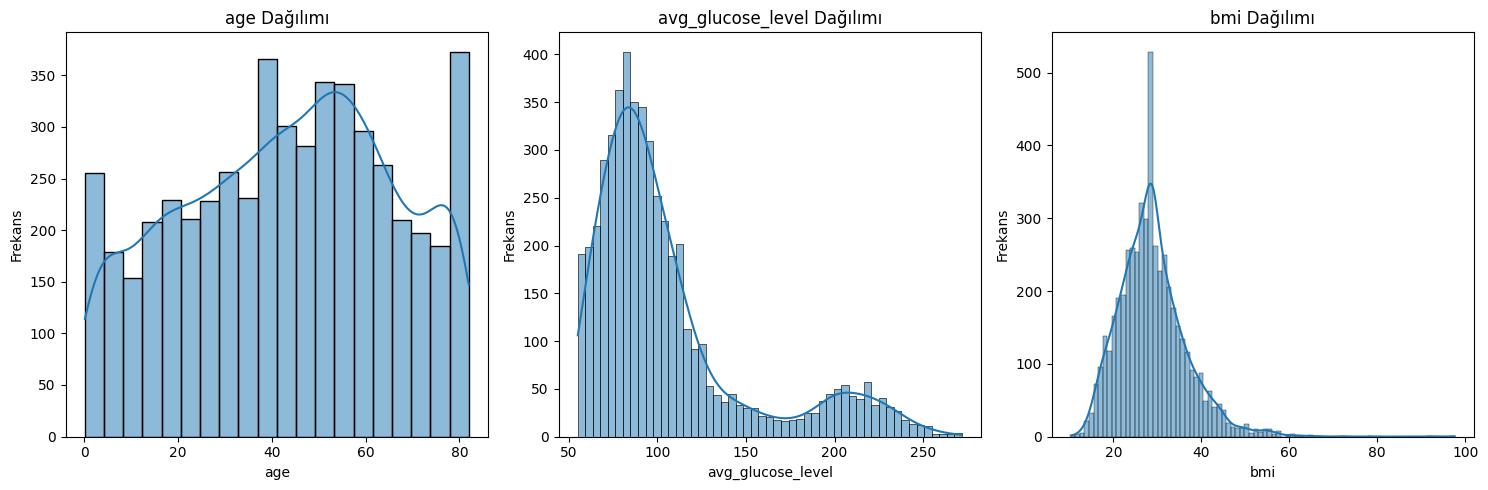

In [ ]:
# burada veri taraflılığını histogram grafiği ile kontrol ediyoruz
numerical_cols_for_hist = ['age', 'avg_glucose_level', 'bmi']

plt.figure(figsize=(15, 5))
for i, col in enumerate(numerical_cols_for_hist):
    plt.subplot(1, 3, i + 1)
    sns.histplot(run_times[col], kde=True)
    plt.title(f'{col} Dağılımı')
    plt.xlabel(col)
    plt.ylabel('Frekans')
plt.tight_layout()
plt.show()


# Eğitim ve Test verilerine ayırma
Makine öğrenmesi modeliniz için özellik matrisini (X) ve hedef değişkeni (y) ayırdık ('stroke' sütunumuz hedef değişken olacak)

## Özellikleri ve Hedef Değişkeni Tanımlama

### amacımız
Makine öğrenmesi modeliniz için özellik matrisini X ve hedef değişkeni y ayırın. Bu durumda hedef değişkenimiz stroke sütunu olacaktır.

#### uygulamaa adomları
1. run_times_encoded DataFrame'inden stroke sütununu hedef değişken y olarak atadık.
2. stroke ve id sütunları dışındaki tüm sütunları özellik matrisi X olarak atadık.

In [ ]:
y = run_times_encoded['stroke']
X = run_times_encoded.drop(['stroke', 'id'], axis=1)

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("\nFirst 5 rows of X:")
print(X.head())
print("\nFirst 5 rows of y:")
print(y.head())

Shape of X: (5109, 14)
Shape of y: (5109,)

First 5 rows of X:
        age  hypertension  heart_disease  ever_married  avg_glucose_level  \
0  1.051242             0              1          True           2.706450   
1  0.785889             0              0          True           2.121652   
2  1.626174             0              1          True          -0.004867   
3  0.255182             0              0          True           1.437473   
4  1.581949             1              0          True           1.501297   

        bmi  gender_Male  work_type_Never_worked  work_type_Private  \
0  1.001041         True                   False               True   
1 -0.000165        False                   False              False   
2  0.468399         True                   False               True   
3  0.715233        False                   False               True   
4 -0.635858        False                   False              False   

   work_type_Self-employed  work_type_children 

## Veriyi Eğitim ve Test Setlerine Ayırma

Modelin aşırı öğrenme yapmadığını ve yeni verilere genellenebildiğini değerlendirmek için veri setinizi eğitim ve test setlerine ayırın. Tipik olarak, train_test_split kullanılır. 20 e 80 olarak ayırıyoruz


In [ ]:
y = run_times_encoded['stroke']
X = run_times_encoded.drop(['stroke', 'id'], axis=1)

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print(X.head())
print(y.head())

Shape of X: (5109, 14)
Shape of y: (5109,)
        age  hypertension  heart_disease  ever_married  avg_glucose_level  \
0  1.051242             0              1          True           2.706450   
1  0.785889             0              0          True           2.121652   
2  1.626174             0              1          True          -0.004867   
3  0.255182             0              0          True           1.437473   
4  1.581949             1              0          True           1.501297   

        bmi  gender_Male  work_type_Never_worked  work_type_Private  \
0  1.001041         True                   False               True   
1 -0.000165        False                   False              False   
2  0.468399         True                   False               True   
3  0.715233        False                   False               True   
4 -0.635858        False                   False              False   

   work_type_Self-employed  work_type_children  Residence_type_Urba

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"\nX_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")


X_train shape: (4087, 14)
X_test shape: (1022, 14)
y_train shape: (4087,)
y_test shape: (1022,)


## Model Eğitimi ve Değerlendirmesi


Seçilen makine öğrenmesi algoritmasını (Random Forest Sınıflandırıcısı) eğitim verileri üzerinde eğitip ardından test seti üzerinde doğruluk, kesinlik, geri çağırma, F1 skoru ve ROC AUC gibi metrikler kullanarak değerlendireceğiz.


RandomForestClassifier (Rastgele Orman Sınıflandırıcı) modeli oluşturuyoruz ve bu modelin eğitim verileri kullanılarak eğitilmesini, test verileri üzerinde tahminler yapılmasını ve tahmin olasılıklarının hesaplanmasını sağlamaa çalışıyoruz.


In [ ]:
# kullanmamız gereken kütüphaneleri ekledik burada
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve


Required libraries imported.


In [ ]:
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"ROC AUC Score: {roc_auc:.4f}")

Accuracy: 0.9393
Precision: 0.5000
Recall: 0.0161
F1 Score: 0.0312
ROC AUC Score: 0.7915


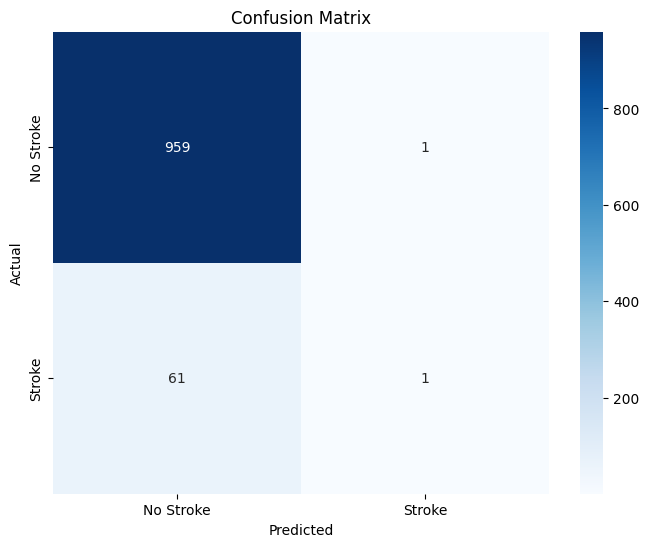

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Confusion matrix oluşturma
cm = confusion_matrix(y_test, y_pred)

# Confusion matrix'i görselleştirme
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Stroke', 'Stroke'],
            yticklabels=['No Stroke', 'Stroke'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


Makine öğrenmesi modeli eğitimini ve değerlendirme sonuçlarını özetleyin, seçilen algoritmanın performansını ve olası sonraki adımları belirtin.


## Hiperparametre Ayarlaması için Kütüphaneleri İçe Aktarma

Hiperparametre ayarlaması için gerekli kütüphaneleri (örneğin, GridSearchCV) içe aktaralım.


In [ ]:
from sklearn.model_selection import GridSearchCV
print("GridSearchCV imported successfully.")

GridSearchCV imported successfully.


In [ ]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10]
}
print("Parameter grid defined successfully.")

Parameter grid defined successfully.


In [ ]:
model = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
grid_search.fit(X_train, y_train)

print("GridSearchCV completed successfully.")

GridSearchCV completed successfully.


In [ ]:
best_model = grid_search.best_estimator_

y_pred_best = best_model.predict(X_test)
y_pred_proba_best = best_model.predict_proba(X_test)[:, 1]

accuracy_best = accuracy_score(y_test, y_pred_best)
precision_best = precision_score(y_test, y_pred_best)
recall_best = recall_score(y_test, y_pred_best)
f1_best = f1_score(y_test, y_pred_best)
roc_auc_best = roc_auc_score(y_test, y_pred_proba_best)

print("Best Model Evaluation Metrics after GridSearchCV:")
print(f"Accuracy: {accuracy_best:.4f}")
print(f"Precision: {precision_best:.4f}")
print(f"Recall: {recall_best:.4f}")
print(f"F1 Score: {f1_best:.4f}")
print(f"ROC AUC Score: {roc_auc_best:.4f}")

Best Model Evaluation Metrics after GridSearchCV:
Accuracy: 0.9393
Precision: 0.0000
Recall: 0.0000
F1 Score: 0.0000
ROC AUC Score: 0.8195


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
best_model = grid_search.best_estimator_

y_pred_best = best_model.predict(X_test)
y_pred_proba_best = best_model.predict_proba(X_test)[:, 1]

accuracy_best = accuracy_score(y_test, y_pred_best)
precision_best = precision_score(y_test, y_pred_best, zero_division=0)
recall_best = recall_score(y_test, y_pred_best, zero_division=0)
f1_best = f1_score(y_test, y_pred_best, zero_division=0)
roc_auc_best = roc_auc_score(y_test, y_pred_proba_best)

print("Best Model Evaluation Metrics after GridSearchCV:")
print(f"Accuracy: {accuracy_best:.4f}")
print(f"Precision: {precision_best:.4f}")
print(f"Recall: {recall_best:.4f}")
print(f"F1 Score: {f1_best:.4f}")
print(f"ROC AUC Score: {roc_auc_best:.4f}")

Best Model Evaluation Metrics after GridSearchCV:
Accuracy: 0.9393
Precision: 0.0000
Recall: 0.0000
F1 Score: 0.0000
ROC AUC Score: 0.8195
